# Holograms without iteration: how far do they get on a trap array

**Question:** How far do holograms computed in one step, with no iteration, get on a 10 by 10 trap array, and what limits each of the three?

- **Level:** 1, Fundamentals
- **Prerequisites:** both notebooks of topic 01
- **Reading time:** about 40 minutes

## Objectives

Before any iteration there are three ways to write a hologram for many traps at once: add the gratings and lenses of all the traps and keep the phase of the sum, add them with a random phase per trap, or give each trap its own random share of the pixels. All three are a single pass over the pixels, which is why they were the first methods and why they are the baseline of every later one. You will run the three on the 100 traps of case C12, read their efficiency, uniformity and spread, and understand from the phase patterns why each lands where it does: why the superposition throws away two thirds of the light, why the random phases cost uniformity, and why the random mask keeps only one percent.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. The next cell imports the tools, prints their versions and puts the pipeline on the path.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import importlib.metadata as md
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import geometry, metrics
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import TrapSet
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.baseline import m01_superposition, m02_random_superposition, m03_random_mask

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def array_numbers(res):
    """Efficiency, uniformity and relative spread (percent) of the trap fields of a result."""
    i = metrics.trap_intensities(res.fields)
    return metrics.efficiency(i), metrics.uniformity(i), metrics.rel_std(i)

numpy 2.4.6
matplotlib 3.11.2


## Data

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Licence class: synthetic case written by the product, no third-party dataset, covered by the repository licence.
- File read: `data/examples/cases.json`, case C12, the 10 by 10 array of the earlier notebook on a 256 by 256 pixel SLM, with five seeds counted up from the case seed.

In [2]:
# case C12: the 10 x 10 array of the published comparison, on the product's 256 x 256 pixel SLM
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C12_calibration"]
setup = setup_of(rec)
target = target_of(rec)
traps = target.traps
budget = Budget(1)
seeds = [rec["seed"] + k for k in range(5)]
n_traps, n_pixels = len(traps), setup.n_pix**2
print(f"{n_traps} traps, {n_pixels} SLM pixels, {n_pixels / n_traps:.0f} pixels per trap")

100 traps, 65536 SLM pixels, 655 pixels per trap


## Method

Each trap $m$ asks for the grating, lens and optional vortex phase $\Delta_j^m$ of notebook 01. Three ways to combine the requests (Di Leonardo et al. 2007, Table 1, https://doi.org/10.1364/OE.15.001913). The superposition (M01) keeps the phase of the sum, $\phi_j = \arg\sum_m \sqrt{w_m}\,e^{i\Delta_j^m}$. The random superposition (M02) adds a random phase $\theta_m$ per trap, $\phi_j = \arg\sum_m \sqrt{w_m}\,e^{i(\Delta_j^m + \theta_m)}$. The random mask (M03; Montes-Usategui et al. 2006, https://opg.optica.org/oe/fulltext.cfm?uri=oe-14-6-2101) splits the pixels into $M$ disjoint random sets of equal size and lets pixel $j$ show only the phase $\Delta_j^{m(j)}$ of the trap that owns it. Published for 10 by 10 on 768 by 768 pixels: efficiency 0.29, uniformity 0.01 and spread 257 percent for the superposition; 0.69, 0.01 and 89 percent for the random superposition; 0.01, 0.58 and 16 percent for the random mask. The cells below run all three, one method per cell.

The superposition first. It uses no random number, so two different seeds must give exactly the same hologram, which the cell checks by the largest phase difference. It also counts the distinct phase values in the hologram, for a reason that the first figure makes visible.

In [3]:
# the superposition has no randomness: two different seeds must give the same hologram
res_a = m01_superposition.run(setup, target, budget=budget, rng=Rng(1))
res_b = m01_superposition.run(setup, target, budget=budget, rng=Rng(2))
e, u, sigma = array_numbers(res_a)
print(f"M01: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")
print(f"largest phase difference between the two seeds: {np.abs(res_a.phi - res_b.phi).max():.1e} rad")
levels = np.unique(np.mod(np.round(res_a.phi, 4), 2 * np.pi).round(4))
print(f"distinct phase values in the hologram: {len(levels)}: {levels}")

M01: e = 0.3280, u = 0.0003, sigma = 268.79 %
largest phase difference between the two seeds: 0.0e+00 rad
distinct phase values in the hologram: 2: [0.     3.1416]


The random superposition draws its trap phases from the seed. The cell runs five seeds, prints the three numbers for each and their mean, so that the spread from seed to seed is visible next to the average.

In [4]:
# random superposition: the same sum with a random phase per trap, five seeds
res_sr = [m02_random_superposition.run(setup, target, budget=budget, rng=Rng(s)) for s in seeds]
table_sr = np.array([array_numbers(r) for r in res_sr])
for s, (e, u, sigma) in zip(seeds, table_sr):
    print(f"M02 seed {s}: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")
m = table_sr.mean(axis=0)
print(f"mean: e = {m[0]:.4f}, u = {m[1]:.4f}, sigma = {m[2]:.2f} %")

M02 seed 20261028: e = 0.7485, u = 0.1994, sigma = 37.40 %
M02 seed 20261029: e = 0.7395, u = 0.2017, sigma = 43.84 %
M02 seed 20261030: e = 0.7203, u = 0.1477, sigma = 40.74 %
M02 seed 20261031: e = 0.7532, u = 0.2626, sigma = 33.29 %
M02 seed 20261032: e = 0.7366, u = 0.1907, sigma = 41.65 %
mean: e = 0.7396, u = 0.2004, sigma = 39.38 %


The random mask also depends on the seed, through the partition of the pixels. The cell runs five seeds, prints the numbers, and reports how many pixels each trap owns, which the method fixes to an equal share.

In [5]:
# random mask: every pixel serves one trap, chosen at random, five seeds
res_rm = [m03_random_mask.run(setup, target, budget=budget, rng=Rng(s)) for s in seeds]
table_rm = np.array([array_numbers(r) for r in res_rm])
for s, (e, u, sigma) in zip(seeds, table_rm):
    print(f"M03 seed {s}: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")
m = table_rm.mean(axis=0)
print(f"mean: e = {m[0]:.4f}, u = {m[1]:.4f}, sigma = {m[2]:.2f} %")
share = np.bincount(res_rm[0].meta["owner"].ravel())
print(f"pixels owned by a trap, least and most: {share.min()} to {share.max()}")
print(f"pixels per trap on a 768 by 768 SLM with 100 traps: {768 * 768 / 100:.0f}")

M03 seed 20261028: e = 0.0099, u = 0.0768, sigma = 54.25 %
M03 seed 20261029: e = 0.0104, u = 0.0620, sigma = 51.16 %
M03 seed 20261030: e = 0.0100, u = 0.0497, sigma = 47.50 %
M03 seed 20261031: e = 0.0100, u = 0.0523, sigma = 53.08 %
M03 seed 20261032: e = 0.0099, u = 0.0463, sigma = 52.01 %
mean: e = 0.0101, u = 0.0574, sigma = 51.60 %
pixels owned by a trap, least and most: 655 to 656
pixels per trap on a 768 by 768 SLM with 100 traps: 5898


Two of the numbers can be predicted. A trap that owns $N/M$ of the pixels receives the sum of those pixels, all in phase with the trap, so $V_m \approx 1/M$ of the amplitude and $I_m \approx 1/M^2$, and the efficiency over $M$ traps is about $1/M$. The other $N - N/M$ pixels add a random sum to each trap whose amplitude relative to the signal is about $M/\sqrt{N}$, and a complex Gaussian error of that relative size changes the intensity by about $\sqrt{2}\,M/\sqrt{N}$ in relative standard deviation (a first-order argument derived for this notebook, not a result from the sources). The cell prints both predictions next to the measurements.

In [6]:
# the two predictions of the text: efficiency 1/M and the spread of a sum with N / M aligned pixels
e_pred = 1.0 / n_traps
sigma_pred = 100.0 * np.sqrt(2.0) * n_traps / np.sqrt(n_pixels)
print(f"predicted efficiency {e_pred:.4f}, measured mean {table_rm[:, 0].mean():.4f}")
print(f"predicted spread {sigma_pred:.1f} %, measured mean spread {table_rm[:, 2].mean():.1f} %")

predicted efficiency 0.0100, measured mean 0.0101
predicted spread 55.2 %, measured mean spread 51.6 %


The first figure shows the central 48 by 48 pixels of one hologram of each method, with the phase on the same colour scale.

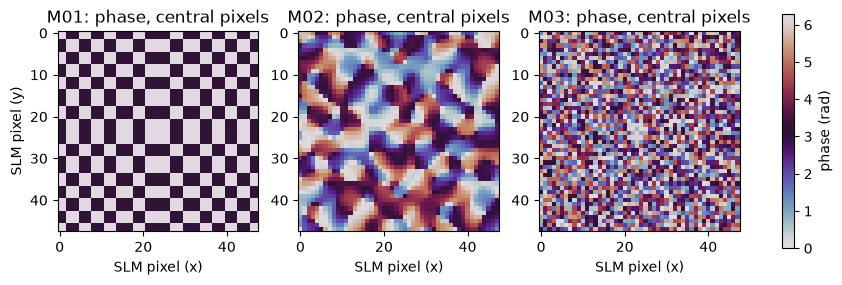

In [7]:
# the central 48 x 48 pixels of one hologram of each method
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
c = setup.n_pix // 2
shown = (("M01", res_a), ("M02", res_sr[0]), ("M03", res_rm[0]))
for ax, (name, res) in zip(axes, shown):
    im = ax.imshow(np.mod(res.phi, 2 * np.pi)[c - 24:c + 24, c - 24:c + 24], cmap="twilight", vmin=0, vmax=2 * np.pi)
    ax.set_title(f"{name}: phase, central pixels")
    ax.set_xlabel("SLM pixel (x)")
axes[0].set_ylabel("SLM pixel (y)")
fig.colorbar(im, ax=axes, label="phase (rad)", shrink=0.8)
plt.show()

The superposition is a chessboard of two phases, 0 and $\pi$, as the count of distinct values said: the array is symmetric about the axis, so the sum of its gratings is a real number and its phase can only be 0 or $\pi$. Two phase levels recall the one-bit device of notebook 01, but they are not what holds the efficiency at 0.3280: in a symmetric array the conjugate order of each trap falls on another trap, so the light lands on the array either way. The next cell tests it by moving the whole array off the axis, which adds a global grating, changes nothing in the trap intensities of a perfect hologram, and breaks the symmetry that makes the phase binary. The random superposition has smooth patches of every phase, because random trap phases break the symmetry and let the sum take any value. The random mask is speckle at the scale of one pixel: neighbouring pixels belong to different traps. The figure does not show the focal plane; it shows only why the three phases look so different.

The cell moves the whole array by two shifts of whole focal bins, runs the superposition on each, and prints its efficiency, uniformity and spread with the number of distinct phase values of the hologram.

In [8]:
# the same array moved off the axis: the phase is no longer binary, are the numbers different?
bin_m = geometry.focal_bin_m(setup)
for dx, dy in ((0, 0), (3, 5), (20, 13)):
    moved = TrapSet(replace(t, x_m=t.x_m + dx * bin_m, y_m=t.y_m + dy * bin_m) for t in traps)
    res = m01_superposition.run(setup, Target.from_traps(moved), budget=budget, rng=Rng(1))
    e, u, sigma = array_numbers(res)
    n_levels = len(np.unique(np.mod(np.round(res.phi, 4), 2 * np.pi).round(4)))
    print(f"shift ({dx:2d}, {dy:2d}) bins: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %, {n_levels} phase values")


shift ( 0,  0) bins: e = 0.3280, u = 0.0003, sigma = 268.79 %, 2 phase values
shift ( 3,  5) bins: e = 0.3280, u = 0.0003, sigma = 268.79 %, 512 phase values
shift (20, 13) bins: e = 0.3280, u = 0.0003, sigma = 268.79 %, 512 phase values


The second figure sorts the power of the 100 traps, relative to the mean, for the three methods on a logarithmic axis.

M01: relative power from 0.00 to 13.36 of the mean
M02: relative power from 0.24 to 2.14 of the mean
M03: relative power from 0.15 to 3.76 of the mean


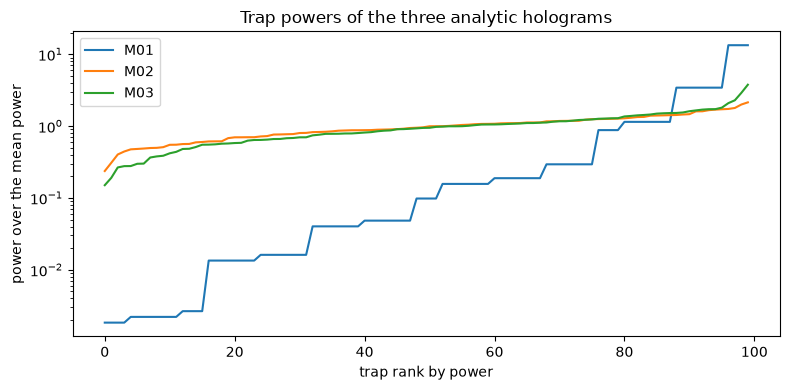

In [9]:
# the power of every trap relative to the mean, sorted, for the three methods
fig, ax = plt.subplots(figsize=(8, 4))
for name, res in shown:
    i = metrics.trap_intensities(res.fields)
    ax.semilogy(np.sort(i / i.mean()), label=name)
    print(f"{name}: relative power from {(i / i.mean()).min():.2f} to {(i / i.mean()).max():.2f} of the mean")
ax.set_xlabel("trap rank by power")
ax.set_ylabel("power over the mean power")
ax.set_title("Trap powers of the three analytic holograms")
ax.legend()
fig.tight_layout()
plt.show()

The superposition spans more than three orders of magnitude, in flat steps set by the symmetry of the lattice. The random superposition spans about one decade, from about 0.24 to 2.1 of the mean, and the random mask a little more, from about 0.15 to 3.8 (the exact ranges are printed above); their spread comes from the same kind of random sum. The figure compares relative powers, so it hides the absolute scale on which they differ most, since the random mask puts about one percent of the input power in the traps while the random superposition puts about three quarters. A hologram with random elements spreads the powers evenly in the log picture but does not equalize them, and the iterations of the next notebooks are the way to equalize.

## Results

**Answer:** Without iteration the three holograms reach very different places on the 100 traps of C12. The superposition is deterministic, with efficiency 0.3280, uniformity 0.0003 and a spread of 268.79 percent; its phase has only two values because the array is symmetric about the axis, and the same array moved off the axis has a phase of hundreds of levels and the same efficiency and spread, so the low numbers are those of the superposition and not of the binary phase. The random superposition gets an efficiency of 0.7396 on average, above the 0.69 published, with a uniformity of 0.2004 and a spread of 39.38 percent where the published values are 0.01 and 89 percent: on this grid the method is more uniform than the paper reports, and the next notebook asks why. The random mask keeps 0.0101 of the light, which matches the prediction of 1/M = 0.0100, with a uniformity of 0.0574 and a spread of 51.60 percent, against 55.2 percent predicted from 655 pixels per trap; the published uniformity of 0.58 and spread of 16 percent for the random mask are for 5898 pixels per trap (768 by 768 pixels, printed above), and the next notebook reaches them on that grid. None of them is a hologram for an experiment: the best of them, the random superposition, leaves a quarter of the light off the traps and its traps differ in power by a factor of about ten, which is what the iterations are for.

## Summary

One-step holograms are fast and carry a signature. The superposition has the widest spread of powers and, for a symmetric array, a binary phase; the random superposition recovers the efficiency at the cost of uniformity; the random mask has an efficiency fixed near one over the number of traps and a spread that falls as the pixels per trap grow. The next notebook measures that dependence on the pixel count and sets the three against the published 10 by 10 table.

## References

- Di Leonardo, Ianni and Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.
- Montes-Usategui, Pleguezuelos, Andilla and Martin-Badosa, "Fast generation of holographic optical tweezers by random mask encoding of Fourier components", Optics Express 14, 2101 (2006), https://opg.optica.org/oe/fulltext.cfm?uri=oe-14-6-2101.